Name: Kushi Niranjana

SRN: PES2UG24CS245

# Unit 2 — Advanced Visualization & Storytelling (UE24CS342AA9)
## Activity Notebook: Building the Global Development Monitor

### Scenario

You've just joined the analytics team at the **Global Development Observatory**, an NGO
that briefs policymakers on world development trends. Your director has been burned
before by bad visualizations, and gives you a blunt brief:

1. *"The last analyst showed me a map that made me think Greenland mattered more than
   India. Don't let that happen again."*
2. *"We're about to publish a model predicting life expectancy. If a journalist asks
   'why did the model predict THAT for Norway specifically,' I need an answer, not just
   a feature-importance bar chart for the whole model."*
3. *"Every number in our reports is an estimate. I want our numbers to LOOK like
   estimates, not like certainties."*
4. *"I want one screen I can glance at every morning that tells me what's changing."*

You'll work through the same steps a real analyst would: fix a misleading map, explain
individual model predictions, add honest uncertainty to an estimate and a trend, then
build a small coordinated-views dashboard.

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection**
are for you to answer in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the real dataset and real country centroids you'll be
working with.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import plotly.express as px
from sklearn.ensemble import RandomForestRegressor
import shap

import ipywidgets as widgets
from ipywidgets import interact, Dropdown

np.random.seed(0)

gapminder = px.data.gapminder()
centroids = pd.read_csv("country_centroids_computed.csv")
gap_latest = gapminder[gapminder.year == 2007].merge(centroids, on="iso_alpha", how="left")
gap_latest = gap_latest.assign(total_gdp=gap_latest["pop"] * gap_latest.gdpPercap)

print(f"Loaded {gapminder.country.nunique()} countries, years {sorted(gapminder.year.unique())}.")
gap_latest[["country", "continent", "year", "lifeExp", "pop", "gdpPercap"]].head()

Loaded 142 countries, years [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)].


,country,continent,year,lifeExp,pop,gdpPercap
0,Afghanistan,Asia,2007,43.828,31889923,974.580338
1,Albania,Europe,2007,76.423,3600523,5937.029526
2,Algeria,Africa,2007,72.301,33333216,6223.367465
3,Angola,Africa,2007,42.731,12420476,4797.231267
4,Argentina,Americas,2007,75.320,40301927,12779.379640


## Task 1 — Fix the Choropleth Trap (Complaint #1)

**Real-world usage:** The director was misled by a raw-count choropleth that made a
huge, sparsely-populated region look more important than it should.

**Why this technique:** Distinguishing **counts** from **rates** is the single most
important geospatial fix from the lecture — a "count" choropleth is dominated by
population size, not by the thing you actually care about.

**TODO:**
1. Build a choropleth of `total_gdp` (a count-like aggregate) using `px.choropleth`.
2. Build a second choropleth of `gdpPercap` (the rate).
3. Print the top-5 countries by each, and compare.

In [2]:
# TODO 1: choropleth of total_gdp

fig1 = px.choropleth(
    gap_latest,
    locations="iso_alpha",
    color="total_gdp",
    hover_name="country",
    color_continuous_scale="Reds",
    title="Total GDP by Country, 2007"
)

fig1.show()


# TODO 2: choropleth of gdpPercap

fig2 = px.choropleth(
    gap_latest,
    locations="iso_alpha",
    color="gdpPercap",
    hover_name="country",
    color_continuous_scale="Reds",
    title="GDP per Capita by Country, 2007"
)

fig2.show()


# TODO 3: top 5 countries by each -- print both lists

top_total = gap_latest.nlargest(
    5,
    "total_gdp"
)[["country", "total_gdp", "gdpPercap"]]

top_rate = gap_latest.nlargest(
    5,
    "gdpPercap"
)[["country", "total_gdp", "gdpPercap"]]

print(
    "Top 5 by total GDP:\n",
    top_total.to_string(index=False)
)

print(
    "\nTop 5 by GDP per capita:\n",
    top_rate.to_string(index=False)
)

Top 5 by total GDP:
       country    total_gdp    gdpPercap
United States 1.293446e+13 42951.653090
        China 6.539501e+12  4959.114854
        Japan 4.035135e+12 31656.068060
        India 2.722925e+12  2452.210407
      Germany 2.650871e+12 32170.374420

Top 5 by GDP per capita:
       country    total_gdp   gdpPercap
       Norway 2.284214e+11 49357.19017
       Kuwait 1.185305e+11 47306.98978
    Singapore 2.146433e+11 47143.17964
United States 1.293446e+13 42951.65309
      Ireland 1.671412e+11 40675.99635


**Reflection:** Which countries appear in one top-5 list but not the other? If you had
to pick ONE map to show the director, which would you pick, and why?

_Your answer:_
The two lists are very different. Norway, Kuwait, Singapore, and Ireland appear in the GDP-per-capita top five but not in the total-GDP top five, while China, Japan, India, and Germany appear in the total-GDP top five but not in the GDP-per-capita top five. I would show the director the GDP-per-capita map because it represents prosperity relative to population rather than being dominated by the size of a country's population. The total-GDP map is useful when the question is about the size of an economy, but it should not be used to represent prosperity or economic performance per person.

## Task 2 — Explain One Specific Prediction (Complaint #2)

**Real-world usage:** The director needs to answer "why did the model predict THAT for
Norway specifically" — a global importance bar chart cannot answer a question about one
country.

**Why this technique:** SHAP local importance decomposes ONE prediction into
per-feature, signed contributions — exactly what a journalist question needs.

**TODO:**
1. Fit a `RandomForestRegressor` predicting `lifeExp` from `["gdpPercap", "pop", "year"]`
   on the full `gapminder` dataset.
2. Build a `shap.TreeExplainer` and compute `shap_values` for all rows.
3. Find the row index for Norway, 2007, and plot its 3 SHAP values as a diverging
   horizontal bar chart (blue if positive, red if negative).

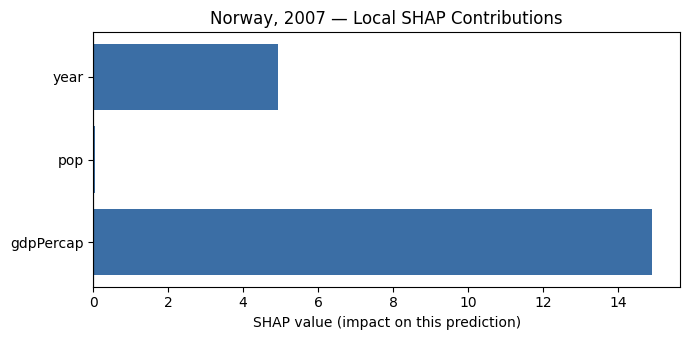

In [3]:
X_model = gapminder[["gdpPercap", "pop", "year"]].values
y_model = gapminder["lifeExp"].values


# TODO 1: fit the model

rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=6,
    random_state=0
)

rf.fit(X_model, y_model)


# TODO 2: SHAP explainer + values

explainer = shap.TreeExplainer(rf)

shap_values = explainer.shap_values(
    X_model
)


# TODO 3: find Norway's row, plot its SHAP contributions

row_idx = gapminder[
    (gapminder["country"] == "Norway") &
    (gapminder["year"] == 2007)
].index[0]

vals = shap_values[row_idx]


# Plot diverging horizontal bars

fig, ax = plt.subplots(
    figsize=(7, 3.5)
)

colors = [
    "#3b6ea5" if v >= 0 else "#b5432e"
    for v in vals
]

ax.barh(
    ["gdpPercap", "pop", "year"],
    vals,
    color=colors
)

ax.axvline(
    0,
    color="black",
    lw=0.8
)

ax.set_xlabel(
    "SHAP value (impact on this prediction)"
)

ax.set_title(
    "Norway, 2007 — Local SHAP Contributions"
)

plt.tight_layout()
plt.show()

**Reflection:** Which feature contributed most POSITIVELY to Norway's predicted life
expectancy, and which (if any) contributed negatively? Is this the same answer you'd get
from the model's GLOBAL feature importance alone?

_Your answer:_

For Norway's 2007 prediction, gdpPercap contributed the most positively, followed by year, while population contributed only a very small positive amount. There were no negatively contributing features for this particular prediction. This is not exactly the same question answered by global feature importance. Global importance tells us which features the model generally relies on across the entire dataset, whereas SHAP local importance tells us how each feature affected this specific Norway prediction and in which direction.

## Task 3 — Make an Estimate Look Like an Estimate (Complaint #3)

**Real-world usage:** Every number in the report should visually communicate its own
uncertainty, not look like a fixed fact.

**Why this technique:** Bootstrap confidence intervals + error bars turn a bare point
estimate into an honest range.

**TODO:**
1. Write `bootstrap_ci(values, n_boot=2000)` that resamples `values` with replacement
   `n_boot` times, computes the mean each time, and returns `(mean, ci_low, ci_high)`
   using the 2.5th and 97.5th percentiles of the bootstrap means.
2. Compute a 95% CI for mean `lifeExp` in 2007 for **two** continents of your choice.
3. Plot both as error bars.

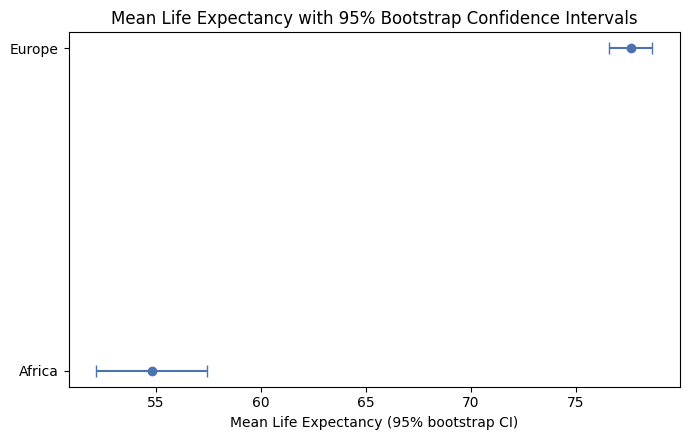

Africa: mean=54.81, 95% CI=(52.15, 57.44)
Europe: mean=77.65, 95% CI=(76.57, 78.65)


In [4]:
def bootstrap_ci(values, n_boot=2000, seed=0):

    rng = np.random.default_rng(seed)

    # TODO 1: bootstrap resampling

    boot_means = [
        rng.choice(
            values,
            size=len(values),
            replace=True
        ).mean()
        for _ in range(n_boot)
    ]

    return (
        np.mean(values),
        np.percentile(boot_means, 2.5),
        np.percentile(boot_means, 97.5)
    )


# TODO 2: compute CIs for two continents

continent_a, continent_b = "Africa", "Europe"

values_a = gap_latest[
    gap_latest.continent == continent_a
].lifeExp.values

values_b = gap_latest[
    gap_latest.continent == continent_b
].lifeExp.values

result_a = bootstrap_ci(values_a)
result_b = bootstrap_ci(values_b)


# TODO 3: plot both as error bars

means = [
    result_a[0],
    result_b[0]
]

ci_low = [
    result_a[1],
    result_b[1]
]

ci_high = [
    result_a[2],
    result_b[2]
]

xerr = [
    np.array(means) - np.array(ci_low),
    np.array(ci_high) - np.array(means)
]

fig, ax = plt.subplots(
    figsize=(7, 4.5)
)

ax.errorbar(
    means,
    [continent_a, continent_b],
    xerr=xerr,
    fmt="o",
    color="#4C72B0",
    capsize=4
)

ax.set_xlabel(
    "Mean Life Expectancy (95% bootstrap CI)"
)

ax.set_title(
    "Mean Life Expectancy with 95% Bootstrap Confidence Intervals"
)

plt.tight_layout()
plt.show()

print(
    f"{continent_a}: mean={result_a[0]:.2f}, "
    f"95% CI=({result_a[1]:.2f}, {result_a[2]:.2f})"
)

print(
    f"{continent_b}: mean={result_b[0]:.2f}, "
    f"95% CI=({result_b[1]:.2f}, {result_b[2]:.2f})"
)

**Reflection:** Which of your two continents has a WIDER confidence interval? Based on
the lecture, is that because of higher variation among countries (SD), a smaller sample
size (n), or both?

_Your answer:_
Africa has the wider confidence interval. In this case, the main reason is the combination of greater variation among countries and a larger spread in life expectancy values, while Europe has a smaller confidence interval because its countries have more similar life expectancy values and therefore a smaller standard deviation. Sample size also affects the width of a confidence interval, but the greater variation in Africa is an important reason for its wider interval.

## Task 4 — Build the Morning Dashboard (Complaint #4)

**Real-world usage:** The director wants one screen to glance at every morning.

**Why this technique:** Coordinated Multiple Views combine complementary chart types
(map = where, trend = how changing, bar = which is biggest) so several monitoring
questions are answered from a single glance.

**TODO:** Build a 1x3 dashboard:
1. A map-style scatter of country centroids, colored by `lifeExp`.
2. A line chart of world-average `lifeExp` by year (use `gapminder.groupby("year")`).
3. A horizontal bar chart of total population by continent in 2007, sorted.

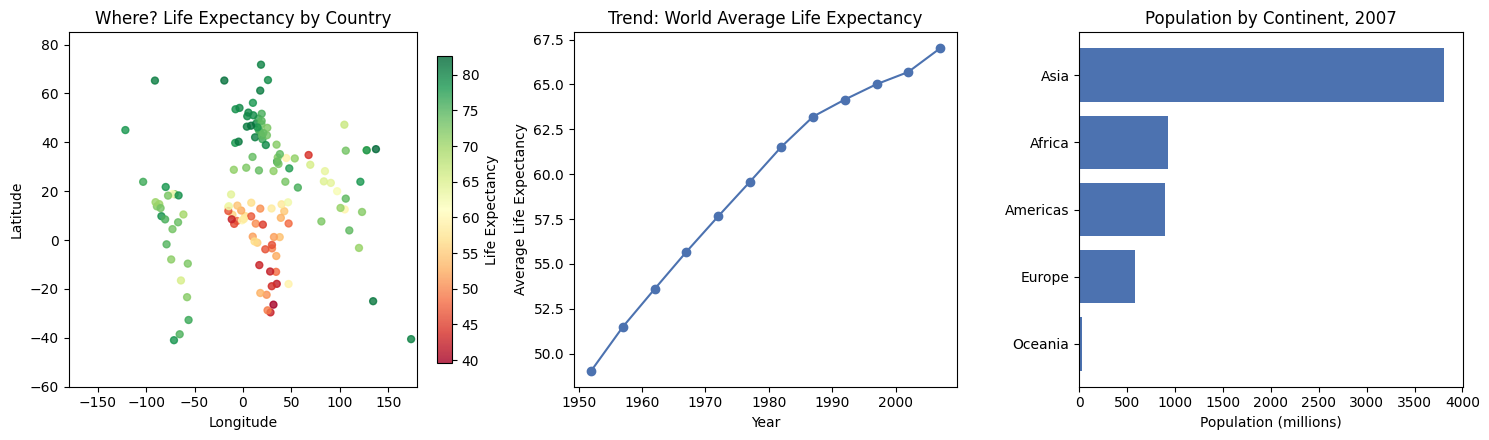

In [5]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4.5)
)

# TODO 1: map-style scatter

d = gap_latest.dropna(
    subset=["centroid_lat", "centroid_lon"]
)

sc = axes[0].scatter(
    d["centroid_lon"],
    d["centroid_lat"],
    c=d["lifeExp"],
    cmap="RdYlGn",
    s=25,
    alpha=0.8
)

axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")

axes[0].set_title(
    "Where? Life Expectancy by Country"
)

axes[0].set_xlim(-180, 180)
axes[0].set_ylim(-60, 85)

plt.colorbar(
    sc,
    ax=axes[0],
    fraction=0.04,
    label="Life Expectancy"
)

# TODO 2: world trend line
world_trend = (
    gapminder
    .groupby("year")["lifeExp"]
    .mean()
    .reset_index()
)

axes[1].plot(
    world_trend["year"],
    world_trend["lifeExp"],
    "o-",
    color="#4C72B0"
)

axes[1].set_xlabel("Year")
axes[1].set_ylabel("Average Life Expectancy")

axes[1].set_title(
    "Trend: World Average Life Expectancy"
)

# TODO 3: population by continent
cont_pop = (
    gapminder[
        gapminder["year"] == 2007
    ]
    .groupby("continent")["pop"]
    .sum()
    .sort_values()
)

axes[2].barh(
    cont_pop.index,
    cont_pop.values / 1e6,
    color="#4C72B0"
)

axes[2].set_xlabel(
    "Population (millions)"
)

axes[2].set_title(
    "Population by Continent, 2007"
)


plt.tight_layout()
plt.show()

**Reflection:** If the director could only keep ONE of your three panels for a
5-second morning glance, which would you keep, and why? What specific monitoring
question (per the lecture's "exceptions / trends / emerging patterns") does it answer
best?

_Your answer:_

I would keep the world-average life expectancy trend line because it provides the most immediate indication of whether the overall situation is improving or worsening over time. In a five-second morning glance, the trend makes an emerging pattern or change immediately visible without requiring the director to compare individual countries. It answers the monitoring question of "what is changing?" most directly. The map is better for answering where differences occur, while the population bar chart answers which continent is largest.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence recommendation to your director covering
the whole notebook. Your answer should:
- State which map framing (count vs. rate) you'd standardize on for all future reports,
  and why.
- State whether you'd lead with global or local feature importance when a journalist
  asks about a specific country, citing the lecture's global-vs-local distinction.
- Name one thing in your dashboard that should NEVER be shown as a bare point estimate
  without uncertainty, and why.

_Your final recommendation here:_

I would standardize on the rate-based map framing, such as GDP per capita, when the goal is to compare prosperity or performance across countries because raw counts can be dominated by population size. When a journalist asks why a model made a prediction for a specific country, I would lead with local feature importance such as SHAP because it explains the signed contribution of each feature to that particular prediction, whereas global importance describes the model's behaviour across the entire dataset. I would still use global importance when explaining which features generally matter most to the model. The mean life expectancy values in the dashboard should never be presented as bare point estimates when they are being used as estimates of a population. They should be accompanied by confidence intervals or another appropriate uncertainty visualization so that the audience does not interpret the estimate as an exact value.